# Notebook 1 · Recolección, limpieza y EDA de titulares peruanos

**Pregunta guía:** *¿Pueden convertir titulares peruanos en un clasificador de noticias?*

| Parámetro | Valor |
|---|---|
| Opción | **C – Comparada** (200 La República + 200 El Comercio = 400) |
| Categorías | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |
| Columnas de salida | `titular`, `bajada`, `medio`, `seccion_original`, `url`, `fecha`, `etiqueta` |
| Salida | `datos/noticias.csv` + respaldos crudos en `datos/raw/` |

**Flujo:** configuración → scraping en capas (RSS → sitemap → HTML → rastreo) → limpieza y mapeo de secciones → muestreo balanceado → EDA con Plotly → validación y exportación.

## 1. Configuración inicial

In [1]:
import sys, json, warnings
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import scraping as sc

warnings.filterwarnings("ignore")
pio.renderers.default = "notebook_connected+png"   # interactivo en Jupyter + PNG visible en GitHub
pd.set_option("display.max_colwidth", 110)

FECHA_DESCARGA = "2026-10-12"
OPCION = "C - Comparada (La República vs. El Comercio)"
CUOTA_CELDA = 50          # noticias por (medio, categoría) -> 4 x 50 = 200 por medio
N_POR_MEDIO = 200
SEED = 42
REDESCARGAR = False       # True fuerza un nuevo scraping aunque exista el respaldo crudo

DIR_RAW = RAIZ / "datos" / "raw"
RESPALDO = DIR_RAW / "candidatos_crudos.json"

# Paleta categórica fija (validada para daltonismo en pares adyacentes)
COLOR_CAT = {"politica": "#2a78d6", "economia": "#eb6834",
             "deportes": "#1baf7a", "ciencia_tecnologia": "#eda100"}
COLOR_MEDIO = {"La República": "#2a78d6", "El Comercio": "#eb6834"}
ORDEN_CAT = list(COLOR_CAT)
PLANTILLA = dict(template="plotly_white", font=dict(family="Arial", size=13), width=1000, height=540,
                 margin=dict(t=120))

print(f"Fecha de descarga: {FECHA_DESCARGA} | Opción: {OPCION}")
fuentes = [
    {"medio": m, "tipo": tipo, "seccion": s, "url": u}
    for m, cfg in sc.FUENTES.items()
    for tipo in ("rss", "sitemaps", "html")
    for s, u in cfg[tipo].items()
]
pd.DataFrame(fuentes)

Fecha de descarga: 2026-10-12 | Opción: C - Comparada (La República vs. El Comercio)


,medio,tipo,seccion,url
0,La República,rss,politica,https://larepublica.pe/rss/politica.xml
1,La República,rss,economia,https://larepublica.pe/rss/economia.xml
2,La República,rss,deportes,https://larepublica.pe/rss/deportes.xml
3,La República,rss,ciencia,https://larepublica.pe/rss/ciencia.xml
4,La República,sitemaps,politica,https://larepublica.pe/sitemap/politica.xml
5,La República,sitemaps,economia,https://larepublica.pe/sitemap/economia.xml
6,La República,sitemaps,deportes,https://larepublica.pe/sitemap/deportes.xml
7,La República,sitemaps,ciencia,https://larepublica.pe/sitemap/ciencia.xml
8,La República,sitemaps,noticias,https://larepublica.pe/sitemap/noticias.xml
9,La República,html,politica,https://larepublica.pe/politica


## 2. Scraping robusto en capas

1. **RSS oficiales** por sección (`feedparser`): fuente preferida, estable y liviana.
2. **Sitemaps de noticias** (La República los declara como públicos en su `robots.txt`).
3. **HTML de sección/archivo** (`BeautifulSoup`): La República `/<seccion>` y El Comercio `/archivo/<seccion>/`.
4. **Rastreo ligero** de notas relacionadas *dentro de la misma sección* cuando una categoría no llega a la cuota (La República prohíbe la paginación `/pag/` en su `robots.txt`, así que no se usa), y visita a la nota para completar `bajada` (`og:description`) y `fecha`.

Reglas de cortesía: User-Agent identificado como estudiante, `time.sleep(1.5)` antes de **cada** request, máximo **1 reintento** (solo ante 429/5xx o error de red). Cada RSS/sitemap se guarda tal cual en `datos/raw/` y cada página HTML de sección como `.html.gz`; el consolidado de candidatos + bitácora de requests queda en `datos/raw/candidatos_crudos.json`.

In [2]:
if RESPALDO.exists() and not REDESCARGAR:
    crudo = json.loads(RESPALDO.read_text(encoding="utf-8"))
    print(f"Usando respaldo crudo del {crudo['fecha_descarga']} (REDESCARGAR=False)")
else:
    rec = sc.Recolector(DIR_RAW)
    rec.recolectar_fuentes()
    rec.rastrear_hasta_cuota(cuota=int(CUOTA_CELDA * 1.2), max_paginas=60, seed=SEED)
    rec.completar_hasta_cuota(cuota=CUOTA_CELDA + 5, seed=SEED)
    rec.guardar_crudo(RESPALDO, FECHA_DESCARGA)
    crudo = json.loads(RESPALDO.read_text(encoding="utf-8"))

bitacora = pd.DataFrame(crudo["bitacora_requests"])
print(f"Requests realizados: {len(bitacora)} | exitosos: {(bitacora.estado == 200).sum()} | "
      f"con reintento: {(bitacora.intento > 0).sum()}")
print("User-Agent:", crudo["user_agent"], "| pausa:", crudo["pausa_seg"], "s")
print("Archivos en datos/raw/:", sorted(p.name for p in DIR_RAW.iterdir()))

Usando respaldo crudo del 2026-10-12 (REDESCARGAR=False)
Requests realizados: 188 | exitosos: 188 | con reintento: 0
User-Agent: Mozilla/5.0 (compatible; TareaPNL-Estudiante/1.0; proyecto academico de clasificacion de titulares) | pausa: 1.5 s
Archivos en datos/raw/: ['candidatos_crudos.json', 'ec_html_deporte_total.html.gz', 'ec_html_economia.html.gz', 'ec_html_politica.html.gz', 'ec_html_tecnologia.html.gz', 'ec_html_tecnologia_ciencias.html.gz', 'ec_rss_deporte_total.xml', 'ec_rss_economia.xml', 'ec_rss_politica.xml', 'ec_rss_tecnologia.xml', 'lr_html_ciencia.html.gz', 'lr_html_deportes.html.gz', 'lr_html_economia.html.gz', 'lr_html_economia_precio_del_dolar.html.gz', 'lr_html_politica.html.gz', 'lr_html_tecnologia.html.gz', 'lr_rss_ciencia.xml', 'lr_rss_deportes.xml', 'lr_rss_economia.xml', 'lr_rss_politica.xml', 'lr_sitemap_ciencia.xml', 'lr_sitemap_deportes.xml', 'lr_sitemap_economia.xml', 'lr_sitemap_noticias.xml', 'lr_sitemap_politica.xml']


In [3]:
cand = pd.DataFrame(crudo["candidatos"])
cand["fuente_principal"] = cand["fuente"].str.split("|").str[0].str.split(":").str[0]
print("Candidatos únicos recolectados:", len(cand))
cand.groupby(["medio", "fuente_principal"]).size().unstack(fill_value=0)

Candidatos únicos recolectados: 1713


fuente_principal,enlace,html,rss,sitemap
medio,,,,
El Comercio,0,313,151,0
La República,994,36,74,145


## 3. Limpieza y normalización

Pasos: (a) duplicados por URL, (b) titulares vacíos, (c) titulares repetidos dentro del mismo medio, (d) mapeo `seccion_original → etiqueta`, (e) descarte de noticias fuera de las 4 categorías, (f) muestreo balanceado 50 × 4 × 2.

In [4]:
log_descartes = []
df = cand.copy()
for col in ["titular", "bajada", "fecha", "seccion_original"]:
    df[col] = df[col].fillna("").astype(str).str.strip()

n0 = len(df)
df = df.drop_duplicates(subset="url")
log_descartes.append(("Duplicado por URL", n0 - len(df)))

n0 = len(df)
df = df[df["titular"].str.len() > 0]
log_descartes.append(("Titular vacío (enlace hallado por rastreo y no visitado)", n0 - len(df)))

n0 = len(df)
df = df.drop_duplicates(subset=["medio", "titular"])
log_descartes.append(("Titular repetido en el mismo medio", n0 - len(df)))

df["etiqueta"] = [sc.mapear_etiqueta(m, s) for m, s in zip(df["medio"], df["seccion_original"])]
print("Registros tras (a)-(c):", len(df))

Registros tras (a)-(c): 840


### Tabla de equivalencias `seccion_original → etiqueta`

In [5]:
mapeo = (df.assign(etiqueta=df["etiqueta"].fillna("— descartada —"))
           .groupby(["medio", "seccion_original", "etiqueta"]).size()
           .reset_index(name="n_candidatos")
           .sort_values(["medio", "etiqueta", "n_candidatos"], ascending=[True, True, False]))
validas = mapeo[mapeo.etiqueta != "— descartada —"]
print(validas.to_markdown(index=False))

| medio        | seccion_original                   | etiqueta           |   n_candidatos |
|:-------------|:-----------------------------------|:-------------------|---------------:|
| El Comercio  | tecnologia/actualidad              | ciencia_tecnologia |            101 |
| El Comercio  | tecnologia/inteligencia-artificial | ciencia_tecnologia |             20 |
| El Comercio  | tecnologia/ciencias                | ciencia_tecnologia |             19 |
| El Comercio  | tecnologia/ciberseguridad          | ciencia_tecnologia |              5 |
| El Comercio  | tecnologia/ecologia                | ciencia_tecnologia |              3 |
| El Comercio  | tecnologia/gadgets                 | ciencia_tecnologia |              2 |
| El Comercio  | tecnologia/moviles                 | ciencia_tecnologia |              2 |
| El Comercio  | tecnologia                         | ciencia_tecnologia |              1 |
| El Comercio  | tecnologia/inventos                | ciencia_tecnologia |      

### Noticias fuera de las 4 categorías (descartadas)

In [6]:
fuera = df[df["etiqueta"].isna()].copy()
fuera["seccion_top"] = fuera["seccion_original"].str.split("/").str[0]
log_descartes.append(("Sección fuera de las 4 categorías", len(fuera)))
print(f"Descartadas por sección fuera de alcance: {len(fuera)}\n")
print(fuera.groupby(["medio", "seccion_top"]).size().rename("n").reset_index()
          .sort_values(["medio", "n"], ascending=[True, False]).to_markdown(index=False))

Descartadas por sección fuera de alcance: 170

| medio        | seccion_top        |   n |
|:-------------|:-------------------|----:|
| El Comercio  | elecciones         |   6 |
| El Comercio  | ecdata             |   5 |
| El Comercio  | opinion            |   5 |
| El Comercio  | archivo-elcomercio |   2 |
| El Comercio  | bbc-news-mundo     |   2 |
| El Comercio  | eldominical        |   1 |
| El Comercio  | ruedas-tuercas     |   1 |
| La República | sociedad           |  63 |
| La República | mundo              |  27 |
| La República | espectaculos       |  19 |
| La República | latinos-en-usa     |  11 |
| La República | verificador        |   5 |
| La República | cultural           |   4 |
| La República | entretenimiento    |   4 |
| La República | opinion            |   4 |
| La República | cine-series        |   3 |
| La República | publirreportajes   |   3 |
| La República | nota-de-prensa     |   2 |
| La República | carlincatura       |   1 |
| La República | horoscopo   

### Oferta editorial visible y muestreo balanceado

Antes de muestrear guardamos la **oferta editorial visible**: noticias que aparecen en RSS, sitemaps o portadas de sección (sin contar las halladas por rastreo). Es la mejor aproximación disponible al volumen que cada medio publica por categoría y se usa en el EDA. Luego se toman 50 noticias por medio y categoría (semilla 42), priorizando las que tienen bajada.

In [7]:
validos = df[df["etiqueta"].notna()].copy()
oferta = validos[validos["fuente"].str.contains(r"rss:|sitemap:|html:")]

noticias = sc.muestrear_balanceado(validos, cuota=CUOTA_CELDA, n_por_medio=N_POR_MEDIO, seed=SEED)
log_descartes.append(("Excedente válido no muestreado (cuota 50 por celda)", len(validos) - len(noticias)))

COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
noticias = noticias[COLUMNAS]
print(pd.DataFrame(log_descartes, columns=["motivo", "registros"]).to_markdown(index=False))
print()
print(pd.crosstab(noticias["medio"], noticias["etiqueta"], margins=True).to_markdown())
print(f"\nSin bajada: {(noticias.bajada == '').sum()} | Sin fecha: {(noticias.fecha == '').sum()}")
print("Rango de fechas de publicación:", noticias.fecha[noticias.fecha != ''].min(), "→", noticias.fecha.max())

| motivo                                                   |   registros |
|:---------------------------------------------------------|------------:|
| Duplicado por URL                                        |           0 |
| Titular vacío (enlace hallado por rastreo y no visitado) |         873 |
| Titular repetido en el mismo medio                       |           0 |
| Sección fuera de las 4 categorías                        |         170 |
| Excedente válido no muestreado (cuota 50 por celda)      |         270 |

| medio        |   ciencia_tecnologia |   deportes |   economia |   politica |   All |
|:-------------|---------------------:|-----------:|-----------:|-----------:|------:|
| El Comercio  |                   50 |         50 |         50 |         50 |   200 |
| La República |                   50 |         50 |         50 |         50 |   200 |
| All          |                  100 |        100 |        100 |        100 |   400 |

Sin bajada: 0 | Sin fecha: 0
Rango de 

## 4. EDA con Plotly

Dentro de las 4 categorías, reparto del flujo general: {'politica': 45.5, 'deportes': 21.8, 'economia': 16.4, 'ciencia_tecnologia': 16.4}


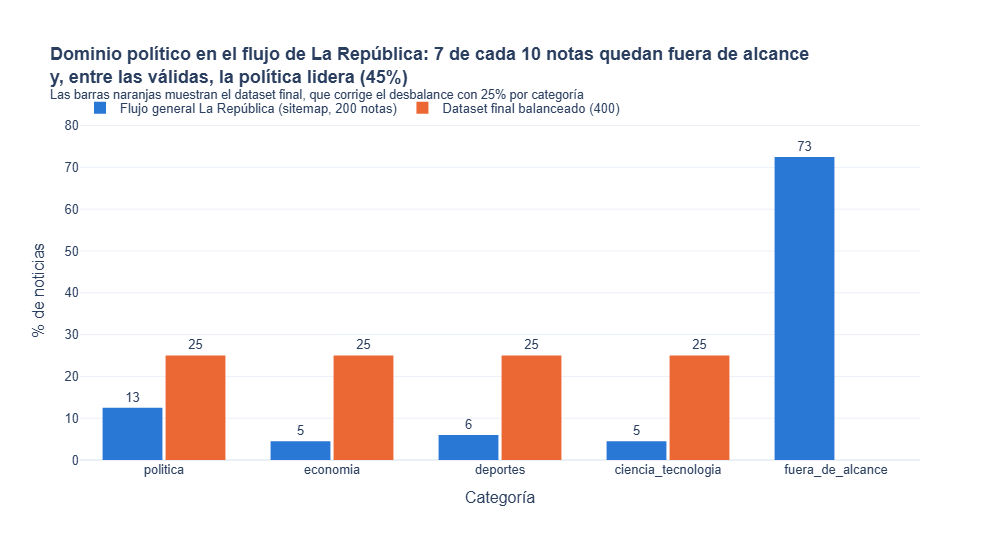

In [8]:
flujo = cand[cand["fuente"].str.contains("sitemap:noticias")].copy()
flujo["categoria"] = [sc.mapear_etiqueta(m, s) or "fuera_de_alcance"
                      for m, s in zip(flujo["medio"], flujo["seccion_original"])]
dist = pd.concat([
    flujo["categoria"].value_counts(normalize=True).rename("pct").reset_index()
         .assign(conjunto=f"Flujo general La República (sitemap, {len(flujo)} notas)"),
    noticias["etiqueta"].rename("categoria").value_counts(normalize=True).rename("pct").reset_index()
         .assign(conjunto="Dataset final balanceado (400)"),
])
dist["pct"] *= 100
validas_flujo = flujo[flujo.categoria != "fuera_de_alcance"]["categoria"].value_counts(normalize=True)
print("Dentro de las 4 categorías, reparto del flujo general:", (100 * validas_flujo).round(1).to_dict())
fig1 = px.bar(dist, x="categoria", y="pct", color="conjunto", barmode="group",
              category_orders={"categoria": ORDEN_CAT + ["fuera_de_alcance"]}, text_auto=".0f",
              color_discrete_sequence=["#2a78d6", "#eb6834"],
              labels={"pct": "% de noticias", "categoria": "Categoría", "conjunto": ""},
              title="<b>Dominio político en el flujo de La República: 7 de cada 10 notas quedan fuera de alcance<br>y, entre las válidas, la política lidera (45%)</b><br><sup>Las barras naranjas muestran el dataset final, que corrige el desbalance con 25% por categoría</sup>")
fig1.update_traces(marker_line_width=0, textposition="outside", textangle=0)
fig1.update_layout(**PLANTILLA, bargap=0.25, bargroupgap=0.05, legend=dict(orientation="h", y=1.08))
fig1.show()

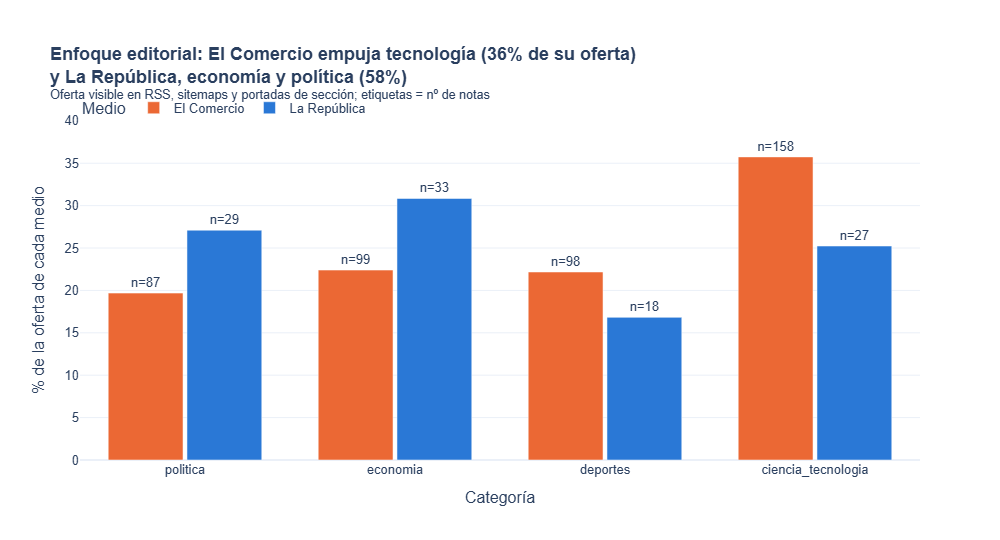

| etiqueta           |   El Comercio |   La República |
|:-------------------|--------------:|---------------:|
| ciencia_tecnologia |           158 |             27 |
| deportes           |            98 |             18 |
| economia           |            99 |             33 |
| politica           |            87 |             29 |


In [9]:
vol = oferta.groupby(["medio", "etiqueta"]).size().rename("n").reset_index()
vol["pct_medio"] = 100 * vol["n"] / vol.groupby("medio")["n"].transform("sum")
fig2 = px.bar(vol, x="etiqueta", y="pct_medio", color="medio", barmode="group",
              category_orders={"etiqueta": ORDEN_CAT}, color_discrete_map=COLOR_MEDIO,
              text="n=" + vol["n"].astype(str), hover_data={"n": True, "pct_medio": ":.1f"},
              labels={"pct_medio": "% de la oferta de cada medio", "etiqueta": "Categoría", "medio": "Medio"},
              title="<b>Enfoque editorial: El Comercio empuja tecnología (36% de su oferta)<br>y La República, economía y política (58%)</b><br><sup>Oferta visible en RSS, sitemaps y portadas de sección; etiquetas = nº de notas</sup>")
fig2.update_traces(textposition="outside", textangle=0)
fig2.update_layout(**PLANTILLA, bargap=0.25, bargroupgap=0.05, legend=dict(orientation="h", y=1.08))
fig2.show()
print(vol.pivot(index="etiqueta", columns="medio", values="n").to_markdown())

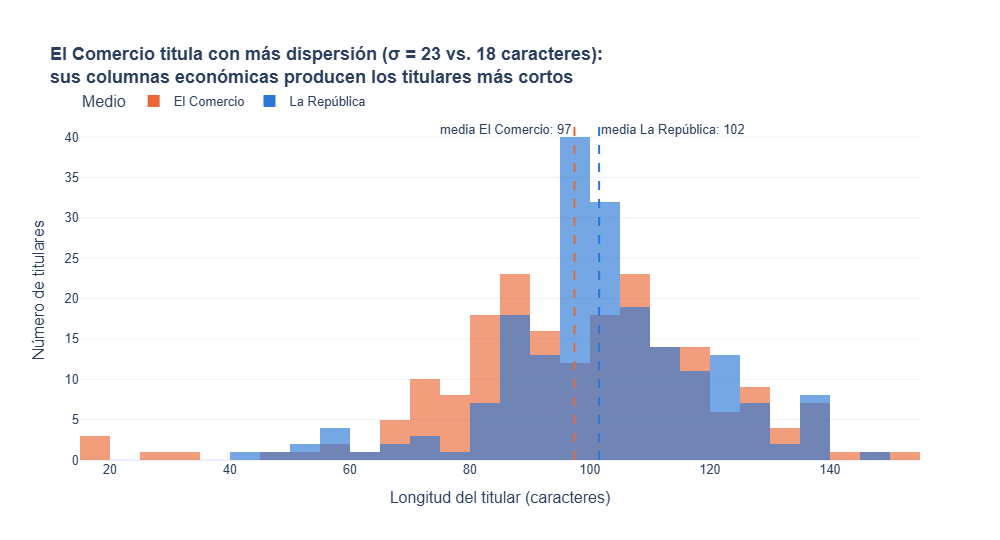

medio                   El Comercio  La República
len_titular      count        200.0         200.0
                 mean          97.4         101.5
                 std           23.0          17.8
                 min           15.0          43.0
                 25%           83.8          94.0
                 50%           99.0         101.0
                 75%          111.0         112.2
                 max          153.0         148.0
palabras_titular count        200.0         200.0
                 mean          16.5          17.3
                 std            4.0           3.3
                 min            2.0           8.0
                 25%           14.0          15.0
                 50%           17.0          17.0
                 75%           19.0          19.0
                 max           27.0          25.0

In [10]:
noticias["len_titular"] = noticias["titular"].str.len()
noticias["palabras_titular"] = noticias["titular"].str.split().str.len()
fig3 = px.histogram(noticias, x="len_titular", color="medio", barmode="overlay",
                    opacity=0.65, color_discrete_map=COLOR_MEDIO,
                    labels={"len_titular": "Longitud del titular (caracteres)", "medio": "Medio"},
                    title="<b>El Comercio titula con más dispersión (σ = 23 vs. 18 caracteres):<br>sus columnas económicas producen los titulares más cortos</b>")
fig3.update_traces(xbins=dict(start=0, end=160, size=5))
for (medio, color), pos in zip(COLOR_MEDIO.items(), ["top right", "top left"]):
    media = noticias.loc[noticias.medio == medio, "len_titular"].mean()
    fig3.add_vline(x=media, line_dash="dash", line_color=color, line_width=2,
                   annotation_text=f"media {medio}: {media:.0f}", annotation_position=pos)
fig3.update_layout(**PLANTILLA, yaxis_title="Número de titulares", legend=dict(orientation="h", y=1.1))
fig3.show()
noticias.groupby("medio")[["len_titular", "palabras_titular"]].describe().round(1).T

In [11]:
resumen = noticias.groupby(["medio", "etiqueta"])["len_titular"].mean().unstack().round(1)
resumen["promedio_medio"] = noticias.groupby("medio")["len_titular"].mean().round(1)
print("Longitud media del titular (caracteres) por medio y categoría:")
print(resumen.to_markdown())

Longitud media del titular (caracteres) por medio y categoría:
| medio        |   ciencia_tecnologia |   deportes |   economia |   politica |   promedio_medio |
|:-------------|---------------------:|-----------:|-----------:|-----------:|-----------------:|
| El Comercio  |                 91.4 |       98.8 |       89.3 |      110.2 |             97.4 |
| La República |                101.2 |      106.8 |       99   |       99   |            101.5 |


### Hallazgos del EDA

1. **La política domina el flujo informativo dentro del alcance, pero la mayor parte del flujo está fuera de él.** En el sitemap general de La República (las 200 notas más recientes), el 72.5% pertenece a secciones fuera de las 4 categorías (sociedad, mundo, espectáculos, latinos en EE. UU.). Entre las 55 notas válidas, la política concentra el 45% y economía y ciencia/tecnología apenas el 16% cada una. Por eso se muestreó con cuota fija (50 por medio y categoría): con un muestreo natural el clasificador vería pocas notas de tecnología.
2. **Los medios tienen enfoques editoriales distintos.** En la oferta visible, El Comercio dedica el 36% a tecnología (con un archivo propio para ciencias), mientras que el 58% de la de La República está en economía y política. Además, el 34% de los titulares deportivos de El Comercio sigue la fórmula de resumen con video ("Goles del partido… | VIDEO"), un atajo léxico que el clasificador puede aprender con facilidad.
3. **La longitud varía más en El Comercio.** La República titula en promedio más largo (101.5 vs. 97.4 caracteres) y con más dos puntos (66% vs. 53% de los titulares), pero El Comercio es más disperso: sus 5 titulares más cortos (< 40 caracteres, p. ej. *"La IA agnóstica"*, *"Norte conectado"*) son columnas de economía sin palabras del dominio. Son los casos más difíciles para cualquier clasificador.

> **Nota metodológica:** la "oferta visible" depende de qué páginas expone cada medio (El Comercio publica archivos de sección con 100 notas; La República solo 12 notas por portada y prohíbe paginar). Por eso las comparaciones entre medios se hacen en porcentaje dentro de cada medio.

## 5. Validación y exportación

In [12]:
cols = ["titular", "medio", "etiqueta", "len_titular"]
print("Top 5 titulares MÁS LARGOS")
display(noticias.nlargest(5, "len_titular")[cols])
print("Top 5 titulares MÁS CORTOS")
display(noticias.nsmallest(5, "len_titular")[cols])

Top 5 titulares MÁS LARGOS


,titular,medio,etiqueta,len_titular
88,"Keiko Fujimori sobre Astudillo: “Le expreso mi total respaldo y gratitud por su valentía. Ministro, los pe...",El Comercio,politica,153
367,"Australia recuperó sus praderas marinas tras un ciclón y grandes inundaciones, pero los científicos descub...",La República,ciencia_tecnologia,148
160,Cristal y el factor Mosquera: los secretos para convertir en 4 meses a un equipo desahuciado en finalista ...,El Comercio,deportes,145
190,Miguel Torres sobre incidentes en el Congreso entre Maraví y ministro Astudillo: “Ningún senador tiene lic...,El Comercio,politica,143
256,"Franco Velazco arremetió contra Pablo Guede y Miguel Rondelli tras polémica con Universitario: ""La solidar...",La República,deportes,139


Top 5 titulares MÁS CORTOS


,titular,medio,etiqueta,len_titular
32,La IA agnóstica,El Comercio,economia,15
199,Norte conectado,El Comercio,economia,15
162,¿Todavía optimista?,El Comercio,economia,19
110,Hay capital mirando al Perú,El Comercio,economia,27
73,Trabajo en equipo: Nuevo enfoque,El Comercio,economia,32


In [13]:
salida = noticias[COLUMNAS].copy()
assert len(salida) == 400 and salida["url"].is_unique and (salida["titular"].str.len() > 0).all()
assert set(salida["etiqueta"]) == set(ORDEN_CAT)
salida.to_csv(RAIZ / "datos" / "noticias.csv", index=False, encoding="utf-8")
print("Guardado datos/noticias.csv")
print("df.shape =", salida.shape)
salida.head()

Guardado datos/noticias.csv
df.shape = (400, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Goles del partido de Barcelona vs Getafe (3-0) por LaLiga EA Sports 2026 | VIDEO,Barcelona goleó 3-0 a Getafe el sábado 10 de octubre por la fecha 8 de LaLiga en el Estadio Camp Nou. Mira...,El Comercio,deporte-total/espana,https://elcomercio.pe/deporte-total/espana/goles-del-partido-de-barcelona-vs-getafe-3-0-por-laliga-ea-spor...,2026-10-10,deportes
1,Wall Street cierra verde tras semana volátil marcada por alza del rendimiento de la deuda,"Según los analistas, el mercado se animó después de que el presidente de EE.UU., Donald Trump, reiterara q...",El Comercio,economia/mercados,https://elcomercio.pe/economia/mercados/wall-street-cierra-verde-tras-semana-volatil-marcada-por-alza-del-...,2026-10-09,economia
2,Carlos Gonzales tras el triunfo de Cristal: “traer a Julio César Uribe y Roberto Mosquera ha sido para dev...,El directivo celeste resaltó la importancia de devolverle al club su esencia y pidió mantener la unidad en...,El Comercio,deporte-total/futbol-peruano,https://elcomercio.pe/deporte-total/futbol-peruano/carlos-gonzales-tras-el-triunfo-de-cristal-traer-a-juli...,2026-10-12,deportes
3,¿Qué es la homoquiralidad que ha protagonizado el Nobel de Química?,Los trabajos de Henri B. Kagan y Kenso Soai explican por qué la vida utiliza solo una de las dos formas es...,El Comercio,tecnologia/ciencias,https://elcomercio.pe/tecnologia/ciencias/que-es-la-homoquiralidad-que-ha-protagonizado-el-nobel-de-quimic...,2026-10-07,ciencia_tecnologia
4,América vs. Medellín (1-2): resumen y goles del partido por Liga Betplay 2026 | VIDEO,"América vs. Medellín EN VIVO: revisa los horarios, canales TV y dónde ver ONLINE por la fecha 14 del Torne...",El Comercio,deporte-total/colombia,https://elcomercio.pe/deporte-total/colombia/video-america-vs-medellin-en-vivo-gratis-hoy-via-win-sports-r...,2026-10-12,deportes


**Siguiente paso:** `02_clasificacion.ipynb` (zero-shot, supervisión débil con LLM, fine-tuning de BETO e innovaciones).